In [36]:
import numpy as np
import pyrepseq as prs
import matplotlib.pyplot as plt

from scipy.special import kv
from scipy import integrate

import repertoire_simulator.lib as lib


plt.style.use("../../project_style.mplstyle")
%config InlineBackend.figure_format = 'retina'

DATA_PATH = "../../data/"

In [43]:
record = np.load(DATA_PATH + "sim_results/two_patches_strong_white_noise.npz",  allow_pickle=True)
c = record["c"][50]

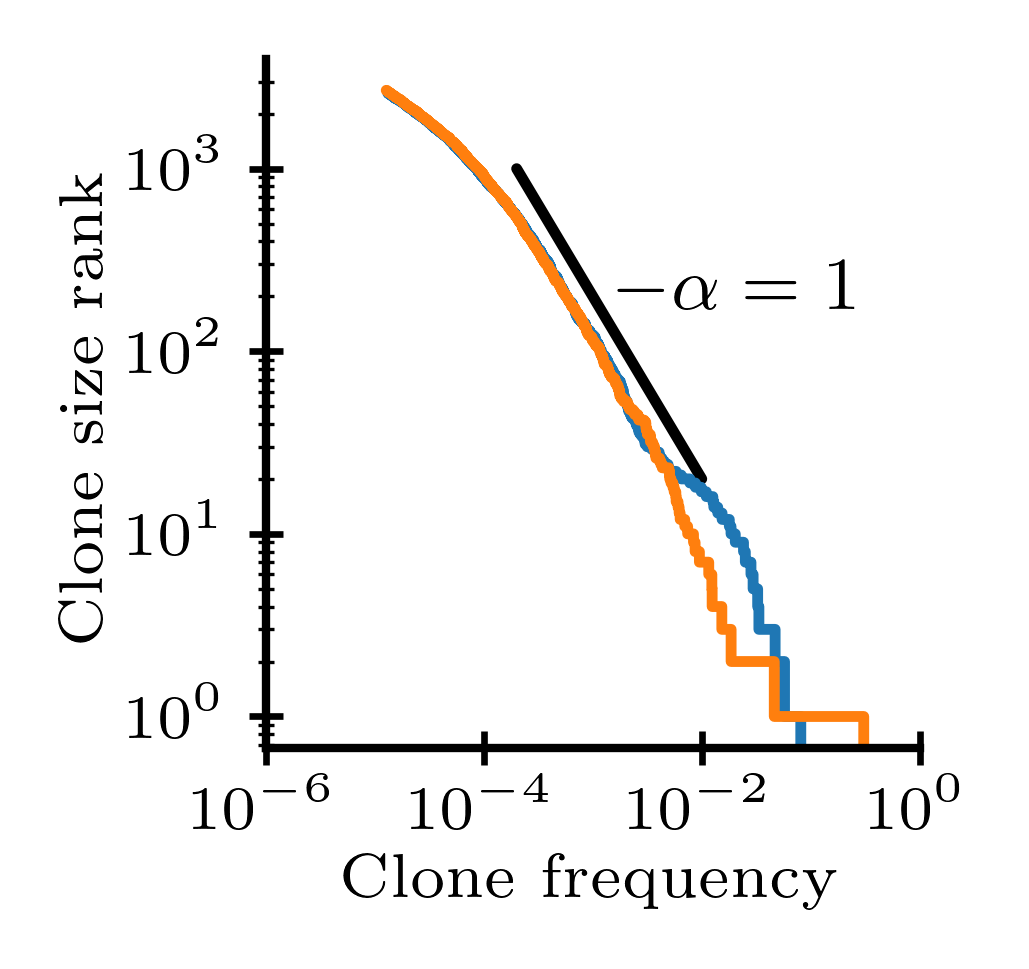

In [44]:
fig, ax = plt.subplots(figsize=(1.6, 1.5), layout='constrained')
lib.plot_referencescaling(ax=ax, x=[2e-4, 1e-2], factor=2e-1, exponent=-1)
for i in range(c.shape[1]):
    prs.plotting.rankfrequency(c[:, i][c[:, i] >= 1], ax=ax, normalize_x=True, label=f'i = {i+1}')
    
ax.set_xlim([1e-6, 1e0]);

# pAFD

In [45]:
def density_x_white_noise(x, M, D):
        
    Z = 2 * kv(0, M / (2 * D))
    
    return 1 / Z * np.exp(- M / (2 * D) * np.cosh(x))

def unnormalized_density_x_coloured_noise(x, M, D, lamb):
    
    return (1 + M/lamb * np.cosh(x)) * np.exp(- M /(2 * D) * (1 + M / (2 * lamb) * np.cosh(x)) * np.cosh(x))

def partition_function_x_coloured_noise(M, D, lamb, x_range=200):
    
    Z = integrate.quad(unnormalized_density_x_coloured_noise, -x_range, x_range, args=(M, D, lamb))[0]
    
    return Z

def density_x_coloured_noise(x, M, D, lamb):
    
    Z = partition_function_x_coloured_noise(M, D, lamb)
    
    return 1 /Z * unnormalized_density_x_coloured_noise(x, M, D, lamb) 

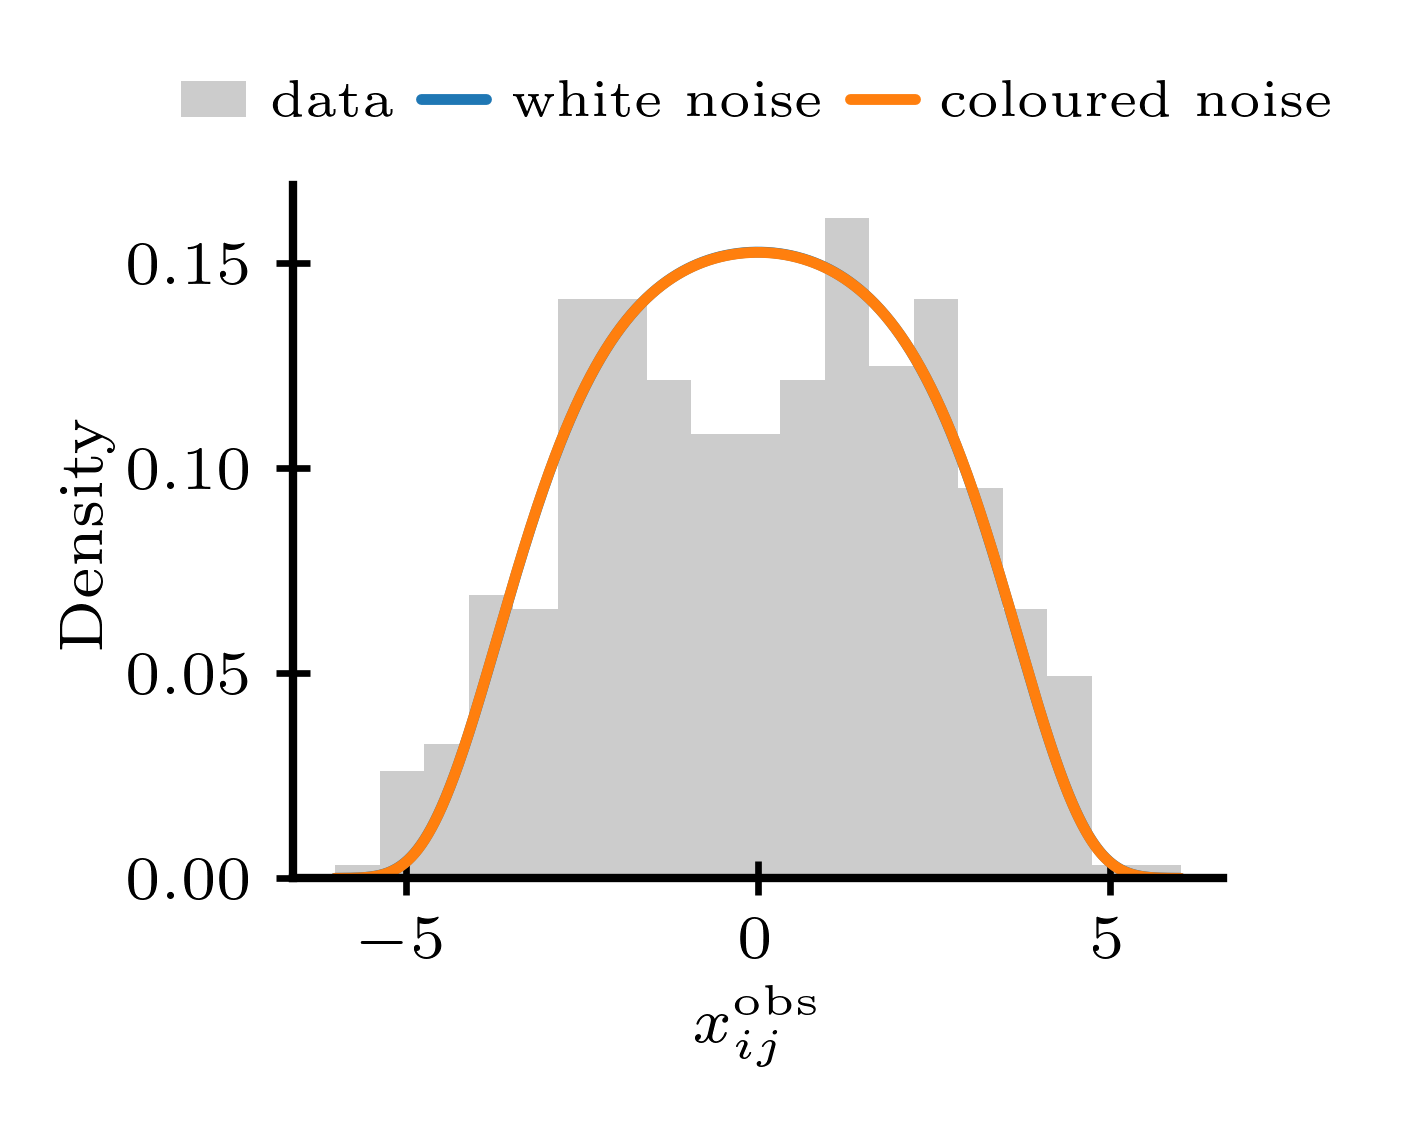

In [46]:
fig, ax = plt.subplots(figsize=(2, 1.5))
x_bound = 6
bins = np.linspace(-x_bound, x_bound, 20)
ax.hist(lib.get_empirical_log_ratios(c[:, 0], c[:, 1], threshold=10, base=np.exp(1)), density=True, bins=bins, alpha=0.2, color='black', label='data')

xs = np.linspace(-x_bound, x_bound, 1000)

M = 0.1
D = 1
lamb = 500

ax.plot(xs, density_x_white_noise(xs, M=M, D=D), label='white noise')
ax.plot(xs, density_x_coloured_noise(xs, M=M, D=D, lamb=lamb), label='coloured noise')

ax.set_xlabel(r'$x^{\mathrm{obs}}_{ij}$')
ax.set_ylabel('Density')
ax.legend(loc="upper center",bbox_to_anchor=(0.5, 1.2), ncol=4, frameon=False);